# mBERT: Full Multilingual Climate Stance Training & Evaluation
**NLP Stance Project**

The complete **6,045-row dataset is embedded** in this notebook: no dataset upload or API key is needed.
Model: `google-bert/bert-base-multilingual-cased`. Target claim: **“Climate change and global warming is a serious concern.”**
Classes: **Against, Favour, None**. This is stance detection, not positive/negative sentiment.



## 1. Install dependencies



In [1]:
%pip -q install "transformers==4.57.1" "datasets>=3.6,<5" "accelerate>=1.1,<2" "scikit-learn>=1.5,<2" "pandas>=2.2,<3" "matplotlib>=3.8,<4" "scipy>=1.11,<2" sentencepiece
# These optional Colab packages can cause unrelated Transformer import failures.
%pip -q uninstall -y librosa torchvision torchaudio


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Configuration



In [2]:
import os, io, gc, re, json, math, time, shutil, hashlib, gzip, base64, unicodedata, zipfile
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
os.environ["WANDB_DISABLED"] = "true"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.special import softmax
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    matthews_corrcoef, cohen_kappa_score, log_loss, roc_auc_score, average_precision_score)
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
    Trainer, TrainingArguments, EarlyStoppingCallback, set_seed)

MODEL_NAME = "google-bert/bert-base-multilingual-cased"
TARGET_CLAIM = "Climate change and global warming is a serious concern."
LABELS = ["Against", "Favour", "None"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = {i: label for label, i in LABEL2ID.items()}
TRAIN_LANGUAGES = ["English", "Hindi", "Bengali"]
MAX_LENGTH = 256
TRAIN_BATCH_SIZE = 8
GRADIENT_ACCUMULATION = 4
EVAL_BATCH_SIZE = 16
MAX_TUNING_EPOCHS = 6
INTERNAL_DEV_FRACTION = 0.20
SPLIT_SEED = 42
FINAL_SEEDS = [42, 123, 2026]
# Compare mild inverse-frequency weighting and ordinary cross-entropy.
TRIALS = [
    {"name": "lr2e5_sqrt_weights", "learning_rate": 2e-5, "weight_power": 0.5},
    {"name": "lr3e5_sqrt_weights", "learning_rate": 3e-5, "weight_power": 0.5},
    {"name": "lr2e5_unweighted", "learning_rate": 2e-5, "weight_power": 0.0},
]
SAVE_TO_DRIVE = False  # Set True before running to preserve large trained models.
DOWNLOAD_RESULTS = True
DOWNLOAD_MODEL_ZIP = False  # Three mBERT models make a large download.
RUN_TEACHER_CSV = False  # Optional upload near the end; never trains on teacher data.

assert torch.cuda.is_available(), "Select a GPU runtime in Colab, then rerun from Section 2."
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUTPUT_ROOT = Path('/content/drive/MyDrive/NLP_Stance_mBERT')
else:
    OUTPUT_ROOT = Path('/content/mbert_climate_stance')
BF16 = torch.cuda.is_bf16_supported()
FP16 = not BF16
set_seed(SPLIT_SEED)
print('GPU:', torch.cuda.get_device_name(0))
print('VRAM (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))
print('Training languages:', TRAIN_LANGUAGES)
print('Precision:', 'bfloat16' if BF16 else 'float16')
print('Versions:', {p: version(p) for p in ['torch', 'transformers', 'datasets', 'accelerate', 'scikit-learn']})


GPU: Tesla T4
VRAM (GB): 14.6
Training languages: ['English', 'Hindi', 'Bengali']
Precision: bfloat16
Versions: {'torch': '2.14.1+cu130', 'transformers': '4.57.1', 'datasets': '4.8.5', 'accelerate': '1.15.0', 'scikit-learn': '1.6.1'}


## 3. Load your full embedded dataset



In [3]:
# @title Load the embedded 6,045-row dataset
EMBEDDED_CSV_GZIP_BASE64 = "..."
EXPECTED_DATASET_SHA256 = "e64c165b259e7669f23da4963b06dbdf779911c8a4c949e24090fbda169403f5"
raw_csv = gzip.decompress(base64.b64decode(EMBEDDED_CSV_GZIP_BASE64))
DATASET_SHA256 = hashlib.sha256(raw_csv).hexdigest()
assert DATASET_SHA256 == EXPECTED_DATASET_SHA256, "The embedded dataset was changed or corrupted."
df = pd.read_csv(io.BytesIO(raw_csv), keep_default_na=False)
df.insert(0, 'row_id', np.arange(len(df)))
required = {'text', 'label', 'language', 'split', 'original_id'}
assert required.issubset(df.columns), f"Missing columns: {required - set(df.columns)}"
for col in required:
    df[col] = df[col].astype(str).str.strip()
assert len(df) == 6045
assert set(df.label) == set(LABELS), f"Unexpected labels: {df.label.unique()}"
assert set(df.language) == {'English', 'Hindi', 'Bengali'}
assert set(df.split) == {'train', 'validation'}
assert df.text.str.len().gt(0).all() and df.original_id.str.len().gt(0).all()
assert df.groupby('original_id').label.nunique().max() == 1, "Translation siblings disagree on labels."
df['label_id'] = df.label.map(LABEL2ID)
print('Rows:', len(df), '| Original source families:', df.original_id.nunique())
display(pd.crosstab([df.split, df.language], df.label).reindex(columns=LABELS))
display(df[['text', 'label', 'language', 'split']].head())


Rows: 6045 | Original source families: 2015


label                Against  Favour  None
split      language                       
train      Bengali       225     681   706
           English       225     681   706
           Hindi         225     681   706
validation Bengali        56     171   176
           English        56     171   176
           Hindi          56     171   176

,text,label,language,split
0,Fracking wells leak massive quantities of meth...,None,English,train
1,Brilliant talk from @GeorgeMonbiot #Dali Lama ...,None,English,train
2,Working with artists & culture is key to weave...,None,English,train
3,A warning sign that some scientists worry coul...,Favour,English,train
4,The Arctic had the power to put the United Sta...,None,English,train


## 4. Leakage audit and safe splits
Keep translation variants with the same `original_id` together. Also connect original families that share
an identical normalized text (Unicode NFKC, collapsed whitespace, case folding). This closes a leakage route
that grouping on `original_id` alone misses. It cannot detect every paraphrase or semantic duplicate.

Preserve the supplied validation rows. Remove connected training families that touch validation, then split
the remaining training families into an internal fitting/development partition, stratified by label.
No validation text or translation sibling can occur in fitting. The original excluded rows still receive predictions.


In [4]:
def normalize_text(text):
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', str(text))).strip().casefold()

df['text_key'] = df.text.map(normalize_text)
parent = {}
def root(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    a, b = root(a), root(b)
    if a != b:
        parent[b] = a

seen_text = {}
for oid, text_key in zip(df.original_id, df.text_key):
    root(oid)
    if text_key in seen_text:
        union(oid, seen_text[text_key])
    else:
        seen_text[text_key] = oid
df['group_id'] = df.original_id.map(root)
assert df.groupby('group_id').label.nunique().max() == 1, (
    'Conflicting labels in a duplicate-connected family. Resolve the annotation conflict before training.')
validation_groups = set(df.loc[df.split.eq('validation'), 'group_id'])
leak_mask = df.split.eq('train') & df.group_id.isin(validation_groups)
excluded = df.loc[leak_mask].copy()
train_pool = df.loc[df.split.eq('train') & ~leak_mask & df.language.isin(TRAIN_LANGUAGES)].copy()
provided_validation = df.loc[df.split.eq('validation')].copy()
group_table = train_pool.groupby('group_id', as_index=False).agg(label_id=('label_id', 'first'))
fit_groups, dev_groups = train_test_split(group_table.group_id, test_size=INTERNAL_DEV_FRACTION,
    random_state=SPLIT_SEED, stratify=group_table.label_id)
internal_fit = train_pool[train_pool.group_id.isin(set(fit_groups))].copy()
internal_dev = train_pool[train_pool.group_id.isin(set(dev_groups))].copy()
for left, right in [(internal_fit, internal_dev), (train_pool, provided_validation)]:
    assert set(left.group_id).isdisjoint(set(right.group_id))
    assert set(left.text_key).isdisjoint(set(right.text_key))
assert set(internal_fit.label_id) == {0, 1, 2} and set(internal_dev.label_id) == {0, 1, 2}
df['evaluation_role'] = 'excluded_from_fitting_language'
df.loc[df.row_id.isin(train_pool.row_id), 'evaluation_role'] = 'final_training_seen'
df.loc[leak_mask, 'evaluation_role'] = 'excluded_train_family_overlaps_validation'
df.loc[df.split.eq('validation'), 'evaluation_role'] = 'provided_validation'

EXPERIMENT = dict(model=MODEL_NAME, claim=TARGET_CLAIM, dataset_sha256=DATASET_SHA256,
    labels=LABELS, train_languages=TRAIN_LANGUAGES, max_length=MAX_LENGTH,
    train_batch_size=TRAIN_BATCH_SIZE, gradient_accumulation=GRADIENT_ACCUMULATION,
    eval_batch_size=EVAL_BATCH_SIZE, max_tuning_epochs=MAX_TUNING_EPOCHS,
    split_seed=SPLIT_SEED, dev_fraction=INTERNAL_DEV_FRACTION, trials=TRIALS,
    final_seeds=FINAL_SEEDS, bf16=BF16,
    versions={p: version(p) for p in ['torch', 'transformers', 'datasets', 'accelerate', 'scikit-learn']})
RUN_ID = hashlib.sha256(json.dumps(EXPERIMENT, sort_keys=True).encode()).hexdigest()[:12]
OUT = OUTPUT_ROOT / RUN_ID
REPORTS = OUT / 'reports'
REPORTS.mkdir(parents=True, exist_ok=True)
def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
save_json(OUT / 'experiment_config.json', EXPERIMENT)
excluded.to_csv(REPORTS / 'excluded_training_overlap_families.csv', index=False)
audit = dict(total_rows=len(df), source_families=int(df.original_id.nunique()),
    original_training_rows=int(df.split.eq('train').sum()),
    provided_validation_rows=len(provided_validation), excluded_training_overlap_rows=len(excluded),
    repeated_text_keys_across_supplied_splits=int((df.groupby('text_key').split.nunique() > 1).sum()),
    final_fit_rows=len(train_pool), internal_fit_rows=len(internal_fit), internal_dev_rows=len(internal_dev))
save_json(REPORTS / 'data_audit.json', audit)
split_manifest = df[['row_id', 'original_id', 'group_id', 'language', 'label', 'split', 'evaluation_role']].copy()
split_manifest['internal_role'] = 'not_used_for_selection'
split_manifest.loc[split_manifest.row_id.isin(internal_fit.row_id), 'internal_role'] = 'fit'
split_manifest.loc[split_manifest.row_id.isin(internal_dev.row_id), 'internal_role'] = 'development'
split_manifest.to_csv(REPORTS / 'split_manifest.csv', index=False)
print(json.dumps(audit, indent=2))
print('Output folder:', OUT)
display(pd.crosstab(train_pool.language, train_pool.label).reindex(columns=LABELS))


{
  "total_rows": 6045,
  "source_families": 2015,
  "original_training_rows": 4836,
  "provided_validation_rows": 1209,
  "excluded_training_overlap_rows": 12,
  "repeated_text_keys_across_supplied_splits": 6,
  "final_fit_rows": 4824,
  "internal_fit_rows": 3858,
  "internal_dev_rows": 966
}
Output folder: /content/mbert_climate_stance/7bf448f65fe3


label,Against,Favour,None
language,,,
Bengali,222,681,705
English,222,681,705
Hindi,222,681,705


## 5. Tokenize claim + comment



In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
collator = DataCollatorWithPadding(tokenizer, pad_to_multiple_of=8)
def make_dataset(frame, include_labels=True):
    items = {'text': frame.text.tolist()}
    if include_labels:
        items['labels'] = frame.label_id.astype(int).tolist()
    data = Dataset.from_dict(items)
    def encode(batch):
        return tokenizer([TARGET_CLAIM] * len(batch['text']), batch['text'],
            truncation='only_second', max_length=MAX_LENGTH)
    return data.map(encode, batched=True, remove_columns=['text'], desc='Tokenizing')

fit_ds = make_dataset(internal_fit)
dev_ds = make_dataset(internal_dev)
pool_ds = make_dataset(train_pool)
full_ds = make_dataset(df, include_labels=False)
claim_tokens = len(tokenizer(TARGET_CLAIM, add_special_tokens=False)['input_ids'])
lengths = tokenizer(df.text.tolist(), add_special_tokens=False, truncation=False, verbose=False)['input_ids']
truncation = df[['language']].copy()
truncation['truncated'] = [len(x) + claim_tokens + 3 > MAX_LENGTH for x in lengths]
display(truncation.groupby('language').truncated.agg(['sum', 'count', 'mean']))
truncation.groupby('language').truncated.agg(['sum', 'count', 'mean']).to_csv(REPORTS / 'truncation_audit.csv')
del lengths


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Tokenizing:   0%|          | 0/3858 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/966 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/4824 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/6045 [00:00<?, ? examples/s]

,sum,count,mean
language,,,
Bengali,5,2015,0.002481
English,0,2015,0.000000
Hindi,1,2015,0.000496


## 6. Metrics and class-aware training



In [6]:
def basic_metrics(y, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y, pred, labels=[0, 1, 2], average='macro', zero_division=0)
    return {'accuracy': float(accuracy_score(y, pred)), 'macro_f1': float(f1),
        'macro_precision': float(precision), 'macro_recall': float(recall),
        'weighted_f1': float(f1_score(y, pred, labels=[0, 1, 2], average='weighted', zero_division=0)),
        'balanced_accuracy': float(balanced_accuracy_score(y, pred))}

def compute_metrics(eval_prediction):
    logits = eval_prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    return basic_metrics(eval_prediction.label_ids, np.argmax(logits, axis=1))

def class_weights(frame, power):
    counts = np.bincount(frame.label_id.to_numpy(), minlength=3)
    assert (counts > 0).all()
    weights = (counts.sum() / (3.0 * counts)) ** power
    return torch.tensor(weights / weights.mean(), dtype=torch.float32)

class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weight_tensor=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weight_tensor = class_weight_tensor
        # Custom loss is a batch mean; let Trainer handle gradient accumulation scaling.
        self.model_accepts_loss_kwargs = False

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        inputs = dict(inputs)
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        weights = self.class_weight_tensor.to(outputs.logits.device)
        loss = F.cross_entropy(outputs.logits.float(), labels, weight=weights)
        return (loss, outputs) if return_outputs else loss

def fresh_model(seed):
    set_seed(seed)
    return AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3,
        id2label=ID2LABEL, label2id=LABEL2ID, attn_implementation='sdpa')

def training_args(output_dir, lr, epochs, seed, tuning):
    return TrainingArguments(output_dir=str(output_dir),
        learning_rate=lr, num_train_epochs=epochs,
        per_device_train_batch_size=TRAIN_BATCH_SIZE,
        per_device_eval_batch_size=EVAL_BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION,
        eval_accumulation_steps=8, weight_decay=0.01, warmup_ratio=0.10,
        lr_scheduler_type='linear', optim='adamw_torch', max_grad_norm=1.0,
        fp16=FP16, bf16=BF16, gradient_checkpointing=True,
        gradient_checkpointing_kwargs={'use_reentrant': False},
        eval_strategy='epoch' if tuning else 'no',
        save_strategy='epoch' if tuning else 'no',
        load_best_model_at_end=tuning, metric_for_best_model='macro_f1',
        greater_is_better=True, save_total_limit=1, save_only_model=True,
        logging_strategy='steps', logging_steps=25, report_to='none',
        seed=seed, data_seed=seed, dataloader_num_workers=0,
        dataloader_pin_memory=True, remove_unused_columns=True)

def clean_gpu():
    gc.collect()
    torch.cuda.empty_cache()


## 7. Select training settings on internal development only



Starting trial: {'name': 'lr2e5_sqrt_weights', 'learning_rate': 2e-05, 'weight_power': 0.5}


model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall,Weighted F1,Balanced Accuracy
1,0.973400,0.868081,0.631470,0.453634,0.444048,0.490776,0.585511,0.490776
2,0.727300,0.795792,0.712215,0.638942,0.721979,0.620066,0.699543,0.620066
3,0.546000,0.884271,0.692547,0.631059,0.692411,0.613819,0.681043,0.613819
4,0.353900,1.058555,0.699793,0.630926,0.694668,0.613508,0.688331,0.613508


Starting trial: {'name': 'lr3e5_sqrt_weights', 'learning_rate': 3e-05, 'weight_power': 0.5}


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (2 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall,Weighted F1,Balanced Accuracy
1,0.933000,0.833070,0.605590,0.433474,0.433331,0.471133,0.559271,0.471133
2,0.697000,0.754235,0.672878,0.513906,0.653541,0.533775,0.632392,0.533775
3,0.542400,0.799320,0.692547,0.608727,0.687674,0.595471,0.675416,0.595471
4,0.365700,0.926635,0.680124,0.602745,0.687412,0.586652,0.665700,0.586652
5,0.243400,1.005598,0.688406,0.627927,0.673335,0.612550,0.678666,0.612550
6,0.170100,1.038720,0.699793,0.644844,0.693948,0.626668,0.691504,0.626668


,name,learning_rate,weight_power,best_epoch,internal_dev_macro_f1,internal_dev_accuracy
1,lr3e5_sqrt_weights,0.00003,0.5,5,0.655000,0.699793
2,lr2e5_unweighted,0.00002,0.0,6,0.644844,0.699793
0,lr2e5_sqrt_weights,0.00002,0.5,2,0.638942,0.712215


Locked settings before provided-validation evaluation: {'name': 'lr3e5_sqrt_weights', 'learning_rate': 3e-05, 'weight_power': 0.5, 'best_epoch': 5, 'internal_dev_macro_f1': 0.6550004369902367, 'internal_dev_accuracy': 0.6997929606625258}


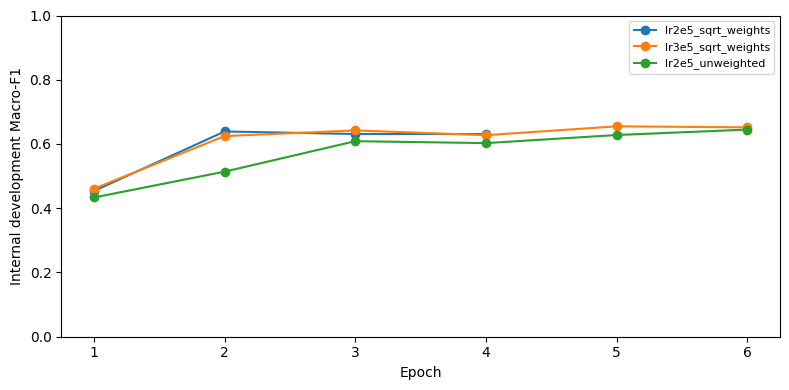

In [7]:
trial_results = []
for trial in TRIALS:
    trial_dir = OUT / 'tuning' / trial['name']
    result_path = trial_dir / 'completed.json'
    if result_path.exists():
        result = json.loads(result_path.read_text())
        print('Reusing completed trial:', trial['name'])
    else:
        print('Starting trial:', trial)
        clean_gpu()
        model = fresh_model(SPLIT_SEED)
        trainer = WeightedTrainer(model=model,
            args=training_args(trial_dir, trial['learning_rate'], MAX_TUNING_EPOCHS, SPLIT_SEED, True),
            train_dataset=fit_ds, eval_dataset=dev_ds, processing_class=tokenizer,
            data_collator=collator, compute_metrics=compute_metrics,
            class_weight_tensor=class_weights(internal_fit, trial['weight_power']),
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
        trainer.train()
        history = trainer.state.log_history
        evaluations = [r for r in history if 'eval_macro_f1' in r]
        # Earliest epoch wins an exact Macro-F1 tie, matching best-checkpoint selection.
        best_log = max(evaluations, key=lambda r: (r['eval_macro_f1'], -r['epoch']))
        result = dict(trial, best_epoch=max(1, int(round(best_log['epoch']))),
            internal_dev_macro_f1=float(best_log['eval_macro_f1']),
            internal_dev_accuracy=float(best_log['eval_accuracy']))
        save_json(trial_dir / 'training_history.json', history)
        save_json(result_path, result)
        save_json(REPORTS / f"tuning_{trial['name']}_history.json", history)
        del trainer, model
        clean_gpu()
        # Retain logs, remove temporary checkpoint weights after the summary is saved.
        for checkpoint in trial_dir.glob('checkpoint-*'):
            shutil.rmtree(checkpoint)
    trial_results.append(result)

leaderboard = pd.DataFrame(trial_results).sort_values(
    ['internal_dev_macro_f1', 'internal_dev_accuracy'], ascending=False, kind='stable')
leaderboard.to_csv(REPORTS / 'internal_dev_hyperparameter_comparison.csv', index=False)
display(leaderboard)
BEST = leaderboard.iloc[0].to_dict()
BEST['best_epoch'] = int(BEST['best_epoch'])
save_json(OUT / 'selected_settings.json', BEST)
print('Locked settings before provided-validation evaluation:', BEST)

fig, ax = plt.subplots(figsize=(8, 4))
for trial in TRIALS:
    history_path = OUT / 'tuning' / trial['name'] / 'training_history.json'
    history = json.loads(history_path.read_text())
    points = [r for r in history if 'eval_macro_f1' in r]
    ax.plot([r['epoch'] for r in points], [r['eval_macro_f1'] for r in points], marker='o', label=trial['name'])
ax.set(xlabel='Epoch', ylabel='Internal development Macro-F1', ylim=(0, 1))
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(REPORTS / 'internal_dev_learning_curves.png', dpi=160)
plt.show()


## 8. Refit on the full eligible training pool and ensemble three seeds
After settings are locked, refit each seed using **all eligible training rows**, including the former internal development rows.
Provided validation is never passed to this fitting stage. Each seed contributes equally to the probability average;
no test-based weights, label offsets, or post-hoc model selection are used.

Completed seeds are reusable from the output folder. The full notebook configuration determines the run folder.
The models and tokenizer are saved for future inference. Scores on training rows are descriptive fitting scores only.


In [8]:
MODEL_ROOT = OUT / 'models'
MODEL_ROOT.mkdir(parents=True, exist_ok=True)
tokenizer.save_pretrained(MODEL_ROOT / 'tokenizer')
probabilities_by_seed = []
timing_rows = []
for seed in FINAL_SEEDS:
    seed_dir = MODEL_ROOT / f'seed_{seed}'
    probability_file = seed_dir / 'full_dataset_probabilities.npy'
    done_file = seed_dir / 'completed.json'
    if done_file.exists() and probability_file.exists():
        probs = np.load(probability_file)
        assert probs.shape == (len(df), 3)
        timing = json.loads(done_file.read_text())
        print('Reusing trained seed:', seed)
    else:
        clean_gpu()
        model = fresh_model(seed)
        trainer = WeightedTrainer(model=model,
            args=training_args(seed_dir / 'training_logs', float(BEST['learning_rate']), BEST['best_epoch'], seed, False),
            train_dataset=pool_ds, processing_class=tokenizer, data_collator=collator,
            class_weight_tensor=class_weights(train_pool, float(BEST['weight_power'])))
        start = time.perf_counter()
        trainer.train()
        train_seconds = time.perf_counter() - start
        trainer.save_model(str(seed_dir))
        save_json(REPORTS / f'final_seed_{seed}_training_history.json', trainer.state.log_history)
        torch.cuda.synchronize()
        start = time.perf_counter()
        prediction = trainer.predict(full_ds)
        torch.cuda.synchronize()
        predict_seconds = time.perf_counter() - start
        logits = prediction.predictions
        if isinstance(logits, tuple):
            logits = logits[0]
        probs = softmax(logits.astype(np.float64), axis=1).astype(np.float32)
        np.save(probability_file, probs)
        timing = dict(seed=int(seed), train_seconds=float(train_seconds),
            full_prediction_seconds=float(predict_seconds), prediction_rows=len(df),
            prediction_rows_per_second=float(len(df) / predict_seconds),
            model_commit=getattr(model.config, '_commit_hash', None))
        save_json(done_file, timing)
        del trainer, model, prediction, logits
        clean_gpu()
    assert np.isfinite(probs).all() and np.allclose(probs.sum(axis=1), 1, atol=1e-4)
    probabilities_by_seed.append(probs)
    timing_rows.append(timing)

ensemble_probs = np.mean(probabilities_by_seed, axis=0)
ensemble_predictions = ensemble_probs.argmax(axis=1)
np.save(REPORTS / 'ensemble_probabilities.npy', ensemble_probs)
pd.DataFrame(timing_rows).to_csv(REPORTS / 'training_and_inference_times.csv', index=False)
print('Final training rows per seed:', len(train_pool))
print('Predicted rows per seed:', len(df), '| Ensemble members:', len(FINAL_SEEDS))


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss
25,1.073600
50,1.044400
75,1.016400
100,0.917900
125,0.879400
150,0.919500
175,0.763500
200,0.747300
225,0.740500
250,0.688800


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss
25,1.095300
50,1.009200
75,0.968800
100,0.902300
125,0.905000
150,0.849600
175,0.763500
200,0.711400
225,0.673000
250,0.652700


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google-bert/bert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss
25,1.081800
50,1.034600
75,1.012100
100,0.972400
125,0.967300
150,0.924900
175,0.750900
200,0.731600
225,0.718000
250,0.717400


Final training rows per seed: 4824
Predicted rows per seed: 6045 | Ensemble members: 3


## 9. Full evaluation: overall, each language, and each class





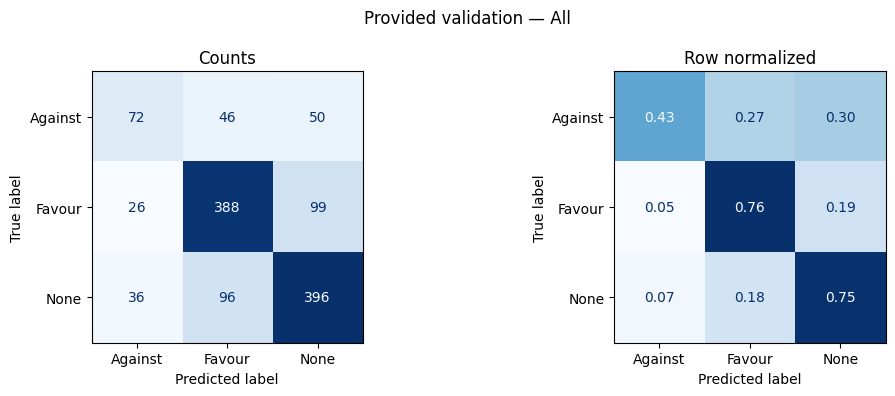

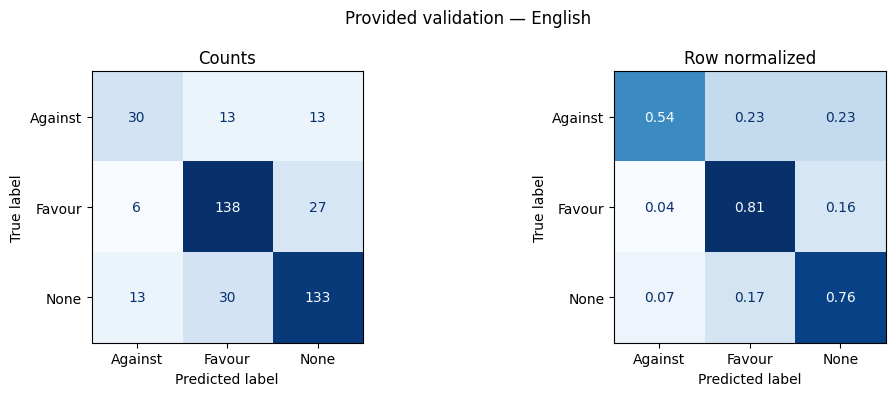

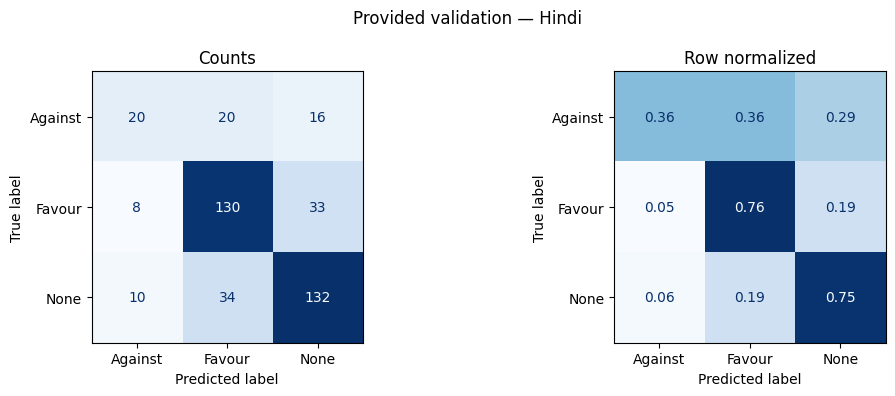

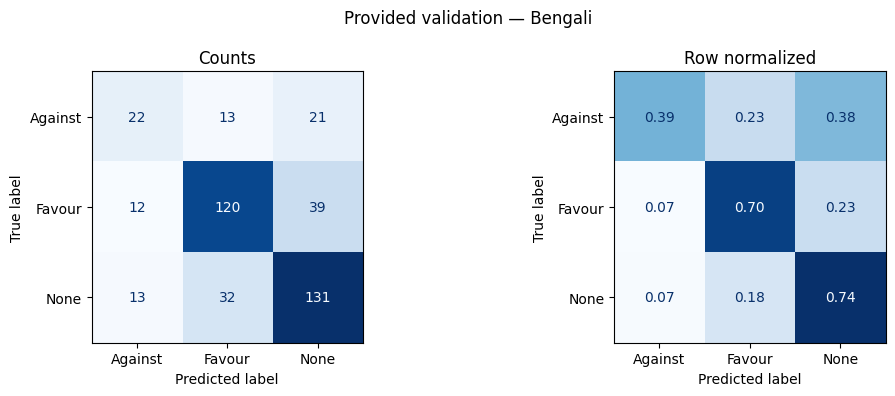

PRIMARY EVALUATION: provided validation (synthetic multilingual data)


,partition,language,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1,balanced_accuracy,n_rows,micro_f1,stance_f1_against_favour,mcc,cohen_kappa,log_loss,roc_auc_ovr_macro,pr_auc_ovr_macro
0,provided_validation,All,0.7080,0.6530,0.6653,0.6450,0.7043,0.6450,1209,0.7080,0.6104,0.5153,0.5148,0.9129,0.8410,0.6965
1,provided_validation,English,0.7469,0.7059,0.7145,0.6995,0.7450,0.6995,403,0.7469,0.6778,0.5822,0.5817,0.8206,0.8684,0.7358
2,provided_validation,Hindi,0.6998,0.6325,0.6540,0.6225,0.6929,0.6225,403,0.6998,0.5790,0.4986,0.4971,0.8972,0.8430,0.6912
3,provided_validation,Bengali,0.6774,0.6185,0.6271,0.6130,0.6742,0.6130,403,0.6774,0.5707,0.4660,0.4651,1.0210,0.8096,0.6694


,partition,language,label,precision,recall,f1-score,support
0,provided_validation,All,Against,0.5373,0.4286,0.4768,168.0
1,provided_validation,All,Favour,0.7321,0.7563,0.7440,513.0
2,provided_validation,All,None,0.7266,0.7500,0.7381,528.0
3,provided_validation,English,Against,0.6122,0.5357,0.5714,56.0
4,provided_validation,English,Favour,0.7624,0.8070,0.7841,171.0
5,provided_validation,English,None,0.7688,0.7557,0.7622,176.0
6,provided_validation,Hindi,Against,0.5263,0.3571,0.4255,56.0
7,provided_validation,Hindi,Favour,0.7065,0.7602,0.7324,171.0
8,provided_validation,Hindi,None,0.7293,0.7500,0.7395,176.0
9,provided_validation,Bengali,Against,0.4681,0.3929,0.4272,56.0


,model,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1,balanced_accuracy,n_rows,micro_f1,stance_f1_against_favour,mcc,cohen_kappa,log_loss,roc_auc_ovr_macro,pr_auc_ovr_macro
0,seed_42,0.6832,0.6284,0.6321,0.6255,0.6816,0.6255,1209,0.6832,0.5803,0.4781,0.4777,1.0673,0.8266,0.6827
1,seed_123,0.6923,0.6321,0.6439,0.6247,0.6880,0.6247,1209,0.6923,0.5853,0.4888,0.4882,1.1246,0.8221,0.6709
2,seed_2026,0.7006,0.6511,0.6602,0.6446,0.6980,0.6446,1209,0.7006,0.6104,0.5046,0.5041,1.0425,0.8291,0.6792
3,equal_probability_ensemble,0.7080,0.6530,0.6653,0.6450,0.7043,0.6450,1209,0.7080,0.6104,0.5153,0.5148,0.9129,0.8410,0.6965


High-confidence validation mistakes — inspect translation fidelity and stance ambiguity:


,text,language,label,predicted_label,confidence
5389,मानवजनित ग्लोबल वार्मिंग का विज्ञान तय हो गया है।,Hindi,None,Against,0.992726
5204,"Global warming, i.e. Climate Change, is not ab...",English,None,Against,0.991735
5607,"ग्लोबल वार्मिंग, यानी जलवायु परिवर्तन, पर्यावर...",Hindi,None,Against,0.990165
6010,"গ্লোবাল ওয়ার্মিং, অর্থাৎ জলবায়ু পরিবর্তন, পর...",Bengali,None,Against,0.989973
5508,ग्लोबल वार्मिंग एक समस्या बन सकती है।,Hindi,None,Favour,0.989892
4936,The winter conditions either debunked or suppo...,English,None,Against,0.989692
5157,Perhaps the most inconvenient fact is the lack...,English,Against,Favour,0.988623
5911,গ্লোবাল ওয়ার্মিং একটি সমস্যা হতে পারে।,Bengali,None,Favour,0.988484
5422,मुझे उन मशहूर हस्तियों से थक गया है जो सोचते ह...,Hindi,Against,None,0.988202
5068,While that this revelation this revelation is ...,English,None,Against,0.988190


In [9]:
def rich_metrics(y, probs):
    y = np.asarray(y, dtype=int)
    pred = probs.argmax(axis=1)
    result = basic_metrics(y, pred)
    per_f1 = f1_score(y, pred, labels=[0, 1, 2], average=None, zero_division=0)
    result.update(n_rows=int(len(y)), micro_f1=float(f1_score(y, pred, average='micro')),
        stance_f1_against_favour=float((per_f1[0] + per_f1[1]) / 2),
        mcc=float(matthews_corrcoef(y, pred)),
        cohen_kappa=float(cohen_kappa_score(y, pred)) if len(np.unique(y)) > 1 else None,
        log_loss=float(log_loss(y, probs, labels=[0, 1, 2])))
    binary_labels = np.eye(3)[y]
    if len(np.unique(y)) == 3:
        result['roc_auc_ovr_macro'] = float(roc_auc_score(y, probs, labels=[0, 1, 2], multi_class='ovr', average='macro'))
        result['pr_auc_ovr_macro'] = float(average_precision_score(binary_labels, probs, average='macro'))
    else:
        result['roc_auc_ovr_macro'] = None
        result['pr_auc_ovr_macro'] = None
    return result

predictions = df.drop(columns=['text_key']).copy()
predictions['predicted_label'] = [ID2LABEL[int(i)] for i in ensemble_predictions]
predictions['confidence'] = ensemble_probs.max(axis=1)
predictions['correct'] = predictions.predicted_label.eq(predictions.label)
for i, label in enumerate(LABELS):
    predictions[f'prob_{label}'] = ensemble_probs[:, i]
for seed, probs in zip(FINAL_SEEDS, probabilities_by_seed):
    predictions[f'prediction_seed_{seed}'] = [ID2LABEL[int(i)] for i in probs.argmax(axis=1)]
predictions.to_csv(REPORTS / 'predictions_all_6045_rows.csv', index=False)

summary_rows, class_rows = [], []
evaluation_masks = {
    'provided_validation': df.split.eq('validation'),
    'training_seen_descriptive_only': df.row_id.isin(train_pool.row_id),
}
for partition, partition_mask in evaluation_masks.items():
    for language in ['All', 'English', 'Hindi', 'Bengali']:
        mask = partition_mask & (True if language == 'All' else df.language.eq(language))
        if not mask.any():
            continue
        idx = np.flatnonzero(mask.to_numpy())
        y = df.iloc[idx].label_id.to_numpy()
        probs = ensemble_probs[idx]
        summary_rows.append(dict(partition=partition, language=language, **rich_metrics(y, probs)))
        report = classification_report(y, probs.argmax(axis=1), labels=[0, 1, 2], target_names=LABELS,
            output_dict=True, zero_division=0)
        for label in LABELS:
            class_rows.append(dict(partition=partition, language=language, label=label, **report[label]))
        if partition == 'provided_validation':
            save_json(REPORTS / f'classification_report_validation_{language}.json', report)
            fig, axes = plt.subplots(1, 2, figsize=(11, 4))
            for ax, normalization, title in zip(axes, [None, 'true'], ['Counts', 'Row normalized']):
                cm = confusion_matrix(y, probs.argmax(axis=1), labels=[0, 1, 2], normalize=normalization)
                ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, colorbar=False,
                    values_format='.2f' if normalization else 'd', cmap='Blues')
                ax.set_title(title)
            fig.suptitle(f'Provided validation — {language}')
            fig.tight_layout()
            fig.savefig(REPORTS / f'confusion_matrix_validation_{language}.png', dpi=160)
            plt.show()

metrics_table = pd.DataFrame(summary_rows)
per_class_table = pd.DataFrame(class_rows)
metrics_table.to_csv(REPORTS / 'metrics_overall_and_per_language.csv', index=False)
per_class_table.to_csv(REPORTS / 'metrics_per_class.csv', index=False)
print('PRIMARY EVALUATION: provided validation (synthetic multilingual data)')
display(metrics_table[metrics_table.partition.eq('provided_validation')].round(4))
display(per_class_table[per_class_table.partition.eq('provided_validation')].round(4))

# Each seed is reported for transparency; do not select a seed after viewing these scores.
val_idx = np.flatnonzero(df.split.eq('validation').to_numpy())
seed_metrics = [dict(model=f'seed_{seed}', **rich_metrics(df.iloc[val_idx].label_id.to_numpy(), probs[val_idx]))
    for seed, probs in zip(FINAL_SEEDS, probabilities_by_seed)]
seed_metrics.append(dict(model='equal_probability_ensemble',
    **rich_metrics(df.iloc[val_idx].label_id.to_numpy(), ensemble_probs[val_idx])))
pd.DataFrame(seed_metrics).to_csv(REPORTS / 'provided_validation_seed_comparison.csv', index=False)
display(pd.DataFrame(seed_metrics).round(4))
errors = predictions.loc[predictions.split.eq('validation') & ~predictions.correct].sort_values('confidence', ascending=False)
errors.to_csv(REPORTS / 'provided_validation_errors.csv', index=False)
print('High-confidence validation mistakes — inspect translation fidelity and stance ambiguity:')
display(errors[['text', 'language', 'label', 'predicted_label', 'confidence']].head(15))


## 10. Family-level bootstrap confidence intervals
The three language variants are correlated. Resample complete connected source families, not individual translated rows.
These 95% bootstrap intervals describe this supplied partition, conditional on the trained ensemble.
They do not account for retraining variability or translation/label errors.


In [10]:
def clustered_intervals(frame, probs, repetitions=1000, seed=2026):
    frame = frame.reset_index(drop=True)
    groups = [np.asarray(v) for v in frame.groupby('group_id', sort=False).indices.values()]
    rng = np.random.default_rng(seed)
    y = frame.label_id.to_numpy()
    pred = probs.argmax(axis=1)
    samples = {'accuracy': [], 'macro_f1': []}
    for _ in range(repetitions):
        chosen = rng.integers(0, len(groups), size=len(groups))
        idx = np.concatenate([groups[i] for i in chosen])
        samples['accuracy'].append(accuracy_score(y[idx], pred[idx]))
        samples['macro_f1'].append(f1_score(y[idx], pred[idx], labels=[0, 1, 2], average='macro', zero_division=0))
    point = basic_metrics(y, pred)
    return [dict(metric=name, estimate=point[name],
        ci95_low=float(np.percentile(values, 2.5)), ci95_high=float(np.percentile(values, 97.5)))
        for name, values in samples.items()]

ci_rows = []
for language in ['All', 'English', 'Hindi', 'Bengali']:
    mask = df.split.eq('validation') & (True if language == 'All' else df.language.eq(language))
    idx = np.flatnonzero(mask.to_numpy())
    ci_rows.extend(dict(language=language, **r) for r in clustered_intervals(df.iloc[idx], ensemble_probs[idx]))
confidence_intervals = pd.DataFrame(ci_rows)
confidence_intervals.to_csv(REPORTS / 'validation_cluster_bootstrap_ci95.csv', index=False)
display(confidence_intervals.round(4))


,language,metric,estimate,ci95_low,ci95_high
0,All,accuracy,0.7080,0.6683,0.7438
1,All,macro_f1,0.6530,0.6050,0.6985
2,English,accuracy,0.7469,0.7047,0.7871
3,English,macro_f1,0.7059,0.6490,0.7557
4,Hindi,accuracy,0.6998,0.6534,0.7413
5,Hindi,macro_f1,0.6325,0.5723,0.6852
6,Bengali,accuracy,0.6774,0.6303,0.7214
7,Bengali,macro_f1,0.6185,0.5596,0.6751


## 12. Save and download results



In [13]:
import io
import zipfile
import pandas as pd
from google.colab import files
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
)

# 1. Upload your existing mBERT results ZIP
print("Upload mBERT_Full_Dataset_Results_7bf448f65fe3.zip")
uploaded = files.upload()

assert len(uploaded) == 1, "Upload exactly one results ZIP."

with zipfile.ZipFile(io.BytesIO(next(iter(uploaded.values())))) as archive:
    matches = [
        name for name in archive.namelist()
        if name.endswith("predictions_all_6045_rows.csv")
    ]
    assert len(matches) == 1, "Prediction CSV not found in this ZIP."

    # Preserve 'None' as a valid class label
    predictions = pd.read_csv(
        archive.open(matches[0]),
        keep_default_na=False
    )

# 2. Evaluate validation rows only
df = predictions[predictions["split"] == "validation"].copy()
assert len(df) > 0, "No validation predictions found."

labels = ["Favour", "Against", "None"]

assert df["label"].isin(labels).all(), "Unexpected actual labels."
assert df["predicted_label"].isin(labels).all(), "Unexpected predictions."

y_true = df["label"]
y_pred = df["predicted_label"]


def macro_score(metric, actual, predicted):
    return metric(
        actual, predicted,
        labels=labels,
        average="macro",
        zero_division=0
    )


# 3. Overall metrics
scores = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision (Macro)": macro_score(precision_score, y_true, y_pred),
    "Recall (Macro)": macro_score(recall_score, y_true, y_pred),
    "Macro F1": macro_score(f1_score, y_true, y_pred),
    "Weighted F1": f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    ),
    "Micro F1": f1_score(
        y_true, y_pred, average="micro", zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
    "MCC": matthews_corrcoef(y_true, y_pred),
}

overall = pd.DataFrame(
    scores.items(),
    columns=["Evaluation Metric", "Score"]
)

# 4. Classification report
report = pd.DataFrame(
    classification_report(
        y_true, y_pred,
        labels=labels,
        target_names=labels,
        output_dict=True,
        zero_division=0
    )
).T

report.loc["accuracy", ["precision", "recall", "f1-score"]] = scores["Accuracy"]
report.loc["accuracy", "support"] = len(df)
report = report.reindex(
    labels + ["accuracy", "macro avg", "weighted avg"]
)

# 5. Confusion matrix: rows = actual, columns = predicted
matrix = pd.DataFrame(
    confusion_matrix(y_true, y_pred, labels=labels),
    index=labels,
    columns=labels
)

# 6. Language-wise metrics
language_rows = []

for language, group in df.groupby("language", sort=False):
    actual = group["label"]
    predicted = group["predicted_label"]

    language_rows.append({
        "Language": language,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": macro_score(precision_score, actual, predicted),
        "Recall": macro_score(recall_score, actual, predicted),
        "Macro F1": macro_score(f1_score, actual, predicted),
        "Samples": len(group),
        "Status": "Computed from validation predictions",
    })

language_metrics = pd.DataFrame(language_rows)

# 7. Create the same report structure as your MuRIL ZIP
output_zip = "mBERT_Evaluation_Results.zip"

with zipfile.ZipFile(output_zip, "w", zipfile.ZIP_DEFLATED) as archive:
    tables = [
        ("overall_metrics.csv", overall, False),
        ("classification_report.csv", report, True),
        ("confusion_matrix.csv", matrix, True),
        ("language_wise_metrics.csv", language_metrics, False),
    ]

    for filename, table, include_index in tables:
        archive.writestr(
            filename,
            table.to_csv(index=include_index, float_format="%.10f")
        )

    archive.writestr(
        "README.txt",
        f"""mBERT Evaluation Results

Validation samples: {len(df)}
Metrics computed from saved validation predictions only.
Training samples are excluded.
Scores use the 0-to-1 scale.

Class order: Favour, Against, None.
Confusion matrix rows: actual labels.
Confusion matrix columns: predicted labels.
Language-wise Precision and Recall use macro averaging.

Hindi/Bengali samples are synthetic translations.
These are supplied-validation results, not independent teacher-test results.
Model weights are not included.
"""
    )

# 8. Display and download
print("\nOverall validation metrics:")
display(overall.round(4))

print("\nClassification report:")
display(report.round(4))

print("\nLanguage-wise metrics:")
display(language_metrics.round(4))

print("\nConfusion matrix:")
display(matrix)

files.download(output_zip)

Upload mBERT_Full_Dataset_Results_7bf448f65fe3.zip


Saving mBERT_Full_Dataset_Results_7bf448f65fe3.zip to mBERT_Full_Dataset_Results_7bf448f65fe3.zip

Overall validation metrics:


,Evaluation Metric,Score
0,Accuracy,0.7080
1,Precision (Macro),0.6653
2,Recall (Macro),0.6450
3,Macro F1,0.6530
4,Weighted F1,0.7043
5,Micro F1,0.7080
6,Balanced Accuracy,0.6450
7,MCC,0.5153



Classification report:


,precision,recall,f1-score,support
Favour,0.7321,0.7563,0.7440,513.0
Against,0.5373,0.4286,0.4768,168.0
None,0.7266,0.7500,0.7381,528.0
accuracy,0.7080,0.7080,0.7080,1209.0
macro avg,0.6653,0.6450,0.6530,1209.0
weighted avg,0.7026,0.7080,0.7043,1209.0



Language-wise metrics:


,Language,Accuracy,Precision,Recall,Macro F1,Samples,Status
0,English,0.7469,0.7145,0.6995,0.7059,403,Computed from validation predictions
1,Hindi,0.6998,0.6540,0.6225,0.6325,403,Computed from validation predictions
2,Bengali,0.6774,0.6271,0.6130,0.6185,403,Computed from validation predictions



Confusion matrix:


,Favour,Against,None
Favour,388,26,99
Against,46,72,50
None,96,36,396


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>